In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
set_font_size(18)

# Disturbance Rejection vs Spring Constant

Visualization of `disturbance_k10_300.npz` — single spring (1 VC, s=1.0 end-effector) subjected to impulse torque disturbance on x-axis for each k ∈ [10, 300] N/m.

**Terminal Setup:**

1. Terminal 1: ~/SoftVMC/MultiVMC/ros2_dynamixel$ ./ros2_run.sh
2. Terminal 2: ~/SoftVMC/MultiVMC$ python3 GUI_MultiVMC_Torque.py
3. Terminal 3: ~/SoftVMC/MultiVMC$ python3 MultiVMC_publish_0.py
4. Terminal 4: ~/SoftVMC/MultiVMC$ python3 GUI_MultiVMC.py
   
![Example Setup](example_setup.png)

**Procedure per k:**
1. In GUI: set k = 10
2. Apply torque disturbance along x in Terminal 5: ros2 topic pub -r 200 -t 100 /goal_torque std_msgs/msg/Float64MultiArray "data: [-0.3, 0.0, 0.0, -0.3, 0.0, -0.3, 0.0, 0.0, 0.0]"
3. Snap back to origin with high k (230)
4. Increment k+10 and repeat step 2.

**Note:** above around k = 100 you don't need to do step 3. since there's not much of a difference. 
**Goal:** Overlay all disturbance responses aligned to t=0 at onset, colored by k (blue→red).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Load main dataset
NPZ = 'outputs/disturbance_rejection/disturbance_k10_300.npz'
d = np.load(NPZ)

# Load corrected k=40 and k=50 data
NPZ_CORRECTED = 'outputs/disturbance_rejection/disturbance_k40_50.npz'
d_corrected = np.load(NPZ_CORRECTED)

# Extract main arrays
t        = d['t']
x        = d['comp_pos'][:, 0, 0]      # end-effector x [m]
k_t      = d['k_params'][:, 0]         # k over time
goal_x   = d['goal'][:, 0, 0]          # reference x
fs       = float(d['control_freq'][0])

print(f"Main file: Duration: {t[-1]-t[0]:.1f} s   n={len(t)}   fs={fs:.0f} Hz")
print(f"Corrected file: {d_corrected['t'][-1] - d_corrected['t'][0]:.1f} s, n={len(d_corrected['t'])}")

# Store corrected data for k=40, k=50 lookup
d_corrected_k40_idx = np.where(np.abs(d_corrected['k_params'][:, 0] - 40.0) < 0.5)[0]
d_corrected_k50_idx = np.where(np.abs(d_corrected['k_params'][:, 0] - 50.0) < 0.5)[0]

print(f"Corrected k=40 samples: {len(d_corrected_k40_idx)}   k=50 samples: {len(d_corrected_k50_idx)}")
print(f"Original k unique: {np.unique(np.round(k_t, 1))}")
print(f"x range: [{x.min():.4f}, {x.max():.4f}] m")

Main file: Duration: 296.9 s   n=97932   fs=330 Hz
Corrected file: 47.2 s, n=15581
Corrected k=40 samples: 5368   k=50 samples: 6289
Original k unique: [  0.  10.  20.  30.  40.  50.  60.  70.  80.  90. 100. 110. 120. 130.
 140. 150. 160. 170. 180. 190. 200. 210. 220. 230. 240. 250. 260. 270.
 280. 290. 300.]
x range: [-0.0278, 0.0806] m


In [2]:
# Segment data by constant k
changes = np.where(np.diff(k_t) != 0)[0] + 1
starts  = np.concatenate([[0], changes])
ends    = np.concatenate([changes, [len(k_t)]])
segs    = [(s, e, float(k_t[s])) for s, e in zip(starts, ends)]

# For k < 100: exclude snap-back phases (k > 200)
# For k >= 100: keep all data
test_segs = [seg for seg in segs if seg[2] not in [200, 230, 250]]
k_values = sorted({seg[2] for seg in test_segs})

print(f"Test segments (excluding snap-back k values): {len(test_segs)}")
print(f"k values to plot: {k_values}")
for s, e, k in test_segs[:5]:
    print(f"  k={k:>5.0f}   t=[{t[s]:6.2f}, {t[e-1]:6.2f}] s   n={e-s}")

Test segments (excluding snap-back k values): 28
k values to plot: [0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0, 110.0, 120.0, 130.0, 140.0, 150.0, 160.0, 170.0, 180.0, 190.0, 210.0, 220.0, 240.0, 260.0, 270.0, 280.0, 290.0, 300.0]
  k=    0   t=[  0.00,  12.70] s   n=4190
  k=   10   t=[ 12.70,  25.83] s   n=4335
  k=   20   t=[ 31.50,  44.48] s   n=4286
  k=   30   t=[ 48.68,  58.38] s   n=3200
  k=   40   t=[ 74.02,  81.97] s   n=2622


## Detect disturbance onset for each k

The disturbance causes the robot to suddenly move in +x. We detect onset by finding when |x| exceeds a threshold (e.g., 0.5 mm) — before that, the robot sits at rest near x=0.

In [3]:
def find_disturbance_onset(x_seg, min_samples=10):
    """Find onset by detecting where x starts consistently increasing.
    
    Look for a sequence of positive derivatives indicating disturbance push has begun.
    """
    dx = np.diff(x_seg)
    # Find the first point where derivatives are consistently positive
    for i in range(len(dx) - min_samples):
        if np.all(dx[i:i+min_samples] > 0):  # all derivatives in window are positive
            return i
    return -1

responses = {}
for k in k_values:
    # Use corrected data for k=40, k=50; otherwise use main dataset
    if k == 40.0:
        if len(d_corrected_k40_idx) > 0:
            x_seg = d_corrected['comp_pos'][d_corrected_k40_idx, 0, 0]
            t_seg = d_corrected['t'][d_corrected_k40_idx]
        else:
            continue
    elif k == 50.0:
        if len(d_corrected_k50_idx) > 0:
            x_seg = d_corrected['comp_pos'][d_corrected_k50_idx, 0, 0]
            t_seg = d_corrected['t'][d_corrected_k50_idx]
        else:
            continue
    else:
        seg = [s for s in test_segs if s[2] == k][0]
        s, e, _ = seg
        x_seg = x[s:e]
        t_seg = t[s:e]
    
    onset_idx = find_disturbance_onset(x_seg, min_samples=10)
    
    if onset_idx >= 0:
        max_duration = 5.0
        max_samples = int(max_duration * fs)
        end_idx = min(onset_idx + max_samples, len(x_seg))
        
        x_resp = x_seg[onset_idx:end_idx]
        t_resp = t_seg[onset_idx:end_idx] - t_seg[onset_idx]
        
        # Find peak and its time
        peak_idx = np.argmax(np.abs(x_resp))
        peak_val = x_resp[peak_idx]
        peak_time = t_resp[peak_idx]
        
        responses[k] = (t_resp, x_resp)
        print(f"k={k:>5.0f}: peak={1000*peak_val:>7.2f}mm @ t={peak_time:.3f}s")

print(f"\nTotal responses extracted: {len(responses)}")

k=   10: peak=  80.60mm @ t=0.555s
k=   20: peak=  76.13mm @ t=0.545s
k=   30: peak=  69.58mm @ t=0.536s
k=   40: peak=  72.21mm @ t=0.533s
k=   50: peak=  65.63mm @ t=0.533s
k=   60: peak=  67.28mm @ t=0.521s
k=   70: peak=  47.68mm @ t=0.521s
k=   80: peak=  54.09mm @ t=0.515s
k=   90: peak=  50.77mm @ t=0.515s
k=  100: peak=  50.18mm @ t=0.516s
k=  110: peak=  44.65mm @ t=0.421s
k=  120: peak=  41.31mm @ t=0.460s
k=  130: peak=  44.99mm @ t=0.509s
k=  140: peak=  47.16mm @ t=0.503s
k=  150: peak=  48.53mm @ t=0.515s
k=  160: peak=  46.26mm @ t=0.424s
k=  170: peak=  43.75mm @ t=0.367s
k=  180: peak=  51.31mm @ t=0.461s
k=  190: peak=  49.27mm @ t=0.472s
k=  210: peak=  46.59mm @ t=0.449s
k=  220: peak=  39.30mm @ t=0.493s
k=  240: peak=  41.11mm @ t=0.348s
k=  260: peak=  40.95mm @ t=0.337s
k=  270: peak=  38.19mm @ t=0.497s
k=  280: peak=  39.44mm @ t=0.491s
k=  290: peak=  39.71mm @ t=0.318s
k=  300: peak=  34.40mm @ t=0.463s

Total responses extracted: 27


## Plot: Disturbance response overlay (time-aligned, colored by k)

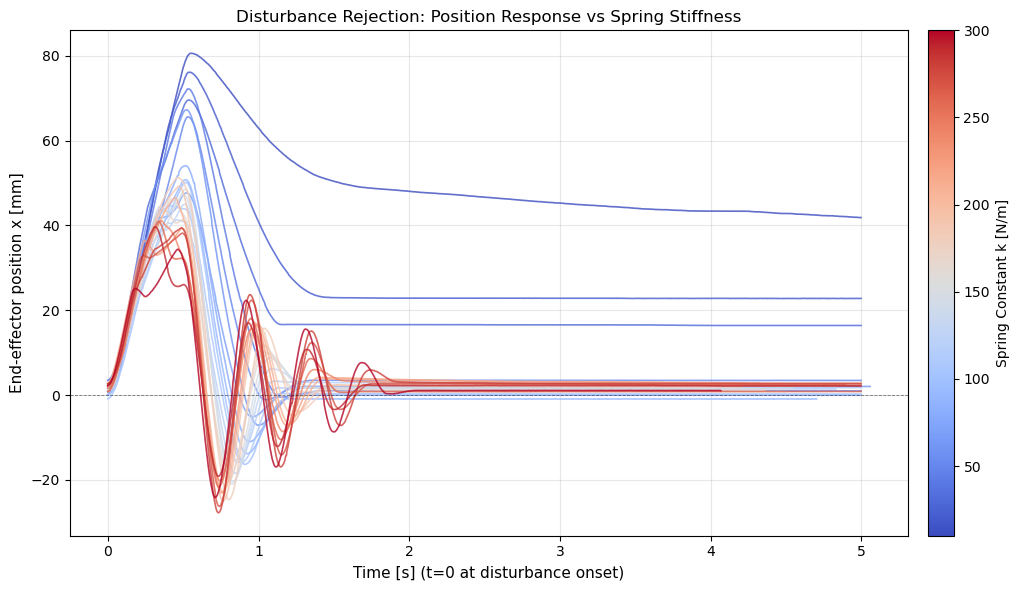

✓ Lower k → softer, larger overshoot. Higher k → stiffer, less overshoot.


In [4]:
fig, ax = plt.subplots(figsize=(11, 6))

cmap = plt.colormaps['coolwarm']
k_min, k_max = min(responses.keys()), max(responses.keys())
norm = plt.Normalize(vmin=k_min, vmax=k_max)

for k in sorted(responses.keys()):
    t_resp, x_resp = responses[k]
    color = cmap(norm(k))
    ax.plot(t_resp, 1000 * x_resp, linewidth=1.2, alpha=0.8, color=color, label=f'k = {k:.0f}')

ax.axhline(0, color='black', linewidth=0.6, linestyle='--', alpha=0.5)
ax.set_xlabel('Time [s] (t=0 at disturbance onset)', fontsize=11)
ax.set_ylabel('End-effector position x [mm]', fontsize=11)
ax.set_title('Disturbance Rejection: Position Response vs Spring Stiffness', fontsize=12)
ax.grid(True, alpha=0.3)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Spring Constant k [N/m]', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join('outputs', 'disturbance_rejection', 'disturbance_response_by_k.pdf'))
plt.show()

print("✓ Lower k → softer, larger overshoot. Higher k → stiffer, less overshoot.")

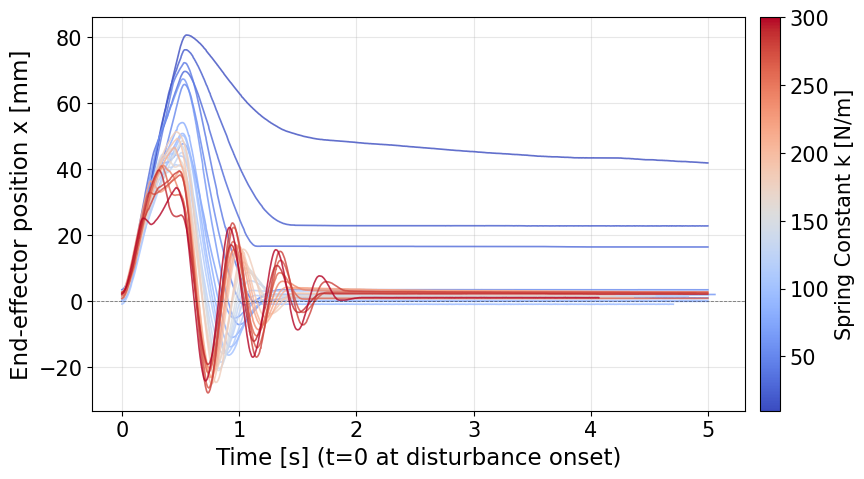

✓ Lower k → softer, larger overshoot. Higher k → stiffer, less overshoot.


In [10]:
SIZE_FACTOR = 1.5   # ← tune this: >1 makes all text bigger (and figure smaller)

# Base sizes (multiplied by SIZE_FACTOR)
FS_LABEL = 11 * SIZE_FACTOR    # axis labels
FS_TICK  = 10 * SIZE_FACTOR    # tick numbers
FS_TITLE = 12 * SIZE_FACTOR    # title
FS_CBAR  = 10 * SIZE_FACTOR    # colorbar label

# Shrink the figure as text grows so the labels dominate
fig_w = 11 / SIZE_FACTOR**0.5
fig_h = 6  / SIZE_FACTOR**0.5

fig, ax = plt.subplots(figsize=(fig_w, fig_h))

cmap = plt.colormaps['coolwarm']
k_min, k_max = min(responses.keys()), max(responses.keys())
norm = plt.Normalize(vmin=k_min, vmax=k_max)

for k in sorted(responses.keys()):
    t_resp, x_resp = responses[k]
    color = cmap(norm(k))
    ax.plot(t_resp, 1000 * x_resp, linewidth=1.2, alpha=0.8, color=color, label=f'k = {k:.0f}')

ax.axhline(0, color='black', linewidth=0.6, linestyle='--', alpha=0.5)
ax.set_xlabel('Time [s] (t=0 at disturbance onset)', fontsize=FS_LABEL)
ax.set_ylabel('End-effector position x [mm]', fontsize=FS_LABEL)
# ax.set_title('Disturbance Rejection: Position Response vs Spring Stiffness', fontsize=FS_TITLE)
ax.tick_params(axis='both', labelsize=FS_TICK)
ax.grid(True, alpha=0.3)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('Spring Constant k [N/m]', fontsize=FS_CBAR)
cbar.ax.tick_params(labelsize=FS_TICK)

plt.tight_layout()
plt.savefig(os.path.join('outputs', 'disturbance_rejection', 'disturbance_response_by_k_scaled.pdf'))
plt.show()

print("✓ Lower k → softer, larger overshoot. Higher k → stiffer, less overshoot.")


## Quantitative metrics per k

In [6]:
metrics = []
for k in sorted(responses.keys()):
    t_resp, x_resp = responses[k]
    
    peak_disp = np.max(np.abs(x_resp))
    has_overshoot = np.min(x_resp) < 0
    min_after_peak = np.min(x_resp)
    
    settle_window = int(0.1 * fs)
    within_tol = np.abs(x_resp) < 0.001
    settled_idx = -1
    for i in range(len(within_tol) - settle_window):
        if np.all(within_tol[i:i+settle_window]):
            settled_idx = i
            break
    settle_time = t_resp[settled_idx] if settled_idx >= 0 else t_resp[-1]
    
    energy = np.sum(x_resp**2)
    
    # Count oscillations: zero crossings in position signal
    zero_crosses = np.sum(np.abs(np.diff(np.sign(x_resp))) > 1.5)
    
    metrics.append({
        'k': k,
        'peak_disp': 1000 * peak_disp,
        'overshoot': has_overshoot,
        'min_x': 1000 * min_after_peak,
        'settle_time': settle_time,
        'energy': energy,
        'oscillations': zero_crosses,
    })

print(f"{'k':>5} | {'peak [mm]':>10} | {'settle [s]':>10} | {'energy':>10} | {'oscil':>6}")
print('-'*60)
for m in metrics:
    print(f"{m['k']:>5.0f} | {m['peak_disp']:>10.2f} | {m['settle_time']:>10.2f} | {m['energy']:>10.5f} | {m['oscillations']:>6.0f}")

    k |  peak [mm] | settle [s] |     energy |  oscil
------------------------------------------------------------
   10 |      80.60 |       5.00 |    4.08087 |      0
   20 |      76.13 |       5.00 |    1.70222 |      0
   30 |      69.58 |       5.00 |    1.12044 |      0
   40 |      72.21 |       1.09 |    0.67599 |      2
   50 |      65.63 |       1.07 |    0.50670 |      2
   60 |      67.28 |       5.06 |    0.54670 |      2
   70 |      47.68 |       5.00 |    0.30713 |      2
   80 |      54.09 |       1.18 |    0.34182 |      3
   90 |      50.77 |       1.17 |    0.29986 |      2
  100 |      50.18 |       1.11 |    0.27402 |      3
  110 |      44.65 |       4.83 |    0.23843 |      2
  120 |      41.31 |       4.07 |    0.21565 |      2
  130 |      44.99 |       5.00 |    0.25254 |      2
  140 |      47.16 |       4.16 |    0.27799 |      2
  150 |      48.53 |       4.54 |    0.26300 |      2
  160 |      46.26 |       1.25 |    0.23266 |      2
  170 |      43.75 | 


=== OPTIMAL K DEFINITIONS ===

1. BALANCED (low peak + fast settle):
   k = 300 N/m
   Peak: 34.40 mm, Settle: 1.82 s

2. SMOOTHEST (least oscillation):
   k = 10 N/m
   Oscillations: 0, Peak: 80.60 mm

3. MOST EFFICIENT (least energy):
   k = 290 N/m
   Energy: 0.17188, Peak: 39.71 mm


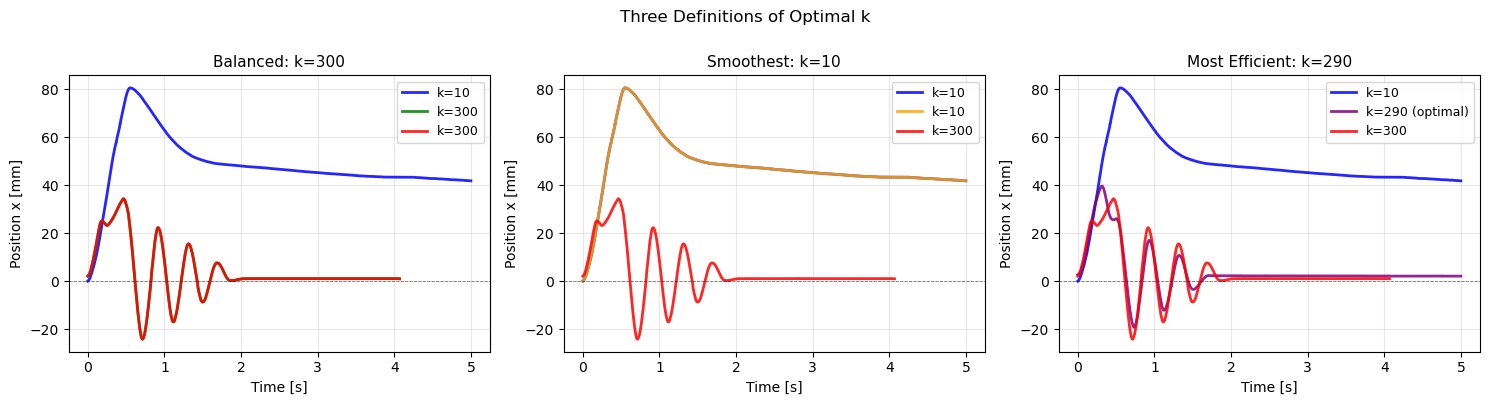

In [7]:
# Find optimal k under different criteria
valid_metrics = [m for m in metrics if m['k'] > 0]

# Normalize metrics to [0,1]
peaks_arr = np.array([m['peak_disp'] for m in valid_metrics])
settle_arr = np.array([m['settle_time'] for m in valid_metrics])
energy_arr = np.array([m['energy'] for m in valid_metrics])
oscil_arr = np.array([m['oscillations'] for m in valid_metrics])

peaks_norm = (peaks_arr - peaks_arr.min()) / (peaks_arr.max() - peaks_arr.min())
settle_norm = (settle_arr - settle_arr.min()) / (settle_arr.max() - settle_arr.min())
energy_norm = (energy_arr - energy_arr.min()) / (energy_arr.max() - energy_arr.min())
oscil_norm = (oscil_arr - oscil_arr.min()) / (oscil_arr.max() - oscil_arr.min() + 1e-6)

# Three different optimization strategies
print("\n=== OPTIMAL K DEFINITIONS ===\n")

# 1. Balanced (peak + settling)
scores_balanced = peaks_norm + settle_norm
idx_balanced = np.argmin(scores_balanced)
k_balanced = valid_metrics[idx_balanced]['k']
print(f"1. BALANCED (low peak + fast settle):")
print(f"   k = {k_balanced:.0f} N/m")
print(f"   Peak: {valid_metrics[idx_balanced]['peak_disp']:.2f} mm, Settle: {valid_metrics[idx_balanced]['settle_time']:.2f} s")

# 2. Smoothest (least oscillation)
idx_smooth = np.argmin(oscil_arr)
k_smooth = valid_metrics[idx_smooth]['k']
print(f"\n2. SMOOTHEST (least oscillation):")
print(f"   k = {k_smooth:.0f} N/m")
print(f"   Oscillations: {valid_metrics[idx_smooth]['oscillations']:.0f}, Peak: {valid_metrics[idx_smooth]['peak_disp']:.2f} mm")

# 3. Most efficient (least energy)
idx_energy = np.argmin(energy_arr)
k_energy = valid_metrics[idx_energy]['k']
print(f"\n3. MOST EFFICIENT (least energy):")
print(f"   k = {k_energy:.0f} N/m")
print(f"   Energy: {valid_metrics[idx_energy]['energy']:.5f}, Peak: {valid_metrics[idx_energy]['peak_disp']:.2f} mm")

# Plot all three comparison sets
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

candidates = [
    ([10, k_balanced, 300], ['blue', 'green', 'red'], 
     f'Balanced: k={k_balanced:.0f}', axes[0]),
    ([10, k_smooth, 300], ['blue', 'orange', 'red'], 
     f'Smoothest: k={k_smooth:.0f}', axes[1]),
    ([10, k_energy, 300], ['blue', 'purple', 'red'], 
     f'Most Efficient: k={k_energy:.0f}', axes[2]),
]

for k_list, colors, title, ax in candidates:
    for k, color in zip(k_list, colors):
        if k in responses:
            t_resp, x_resp = responses[k]
            label = f'k={k:.0f}' if k in [10, 300] else f'k={k:.0f} (optimal)'
            ax.plot(t_resp, 1000 * x_resp, linewidth=2.0, color=color, alpha=0.85, label=label)
    
    ax.axhline(0, color='black', linewidth=0.6, linestyle='--', alpha=0.5)
    ax.set_xlabel('Time [s]', fontsize=10)
    ax.set_ylabel('Position x [mm]', fontsize=10)
    ax.set_title(title, fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Three Definitions of Optimal k', fontsize=12, y=1.00)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig(os.path.join('outputs', 'disturbance_rejection', 'optimal_k_comparison.pdf'))
plt.show()

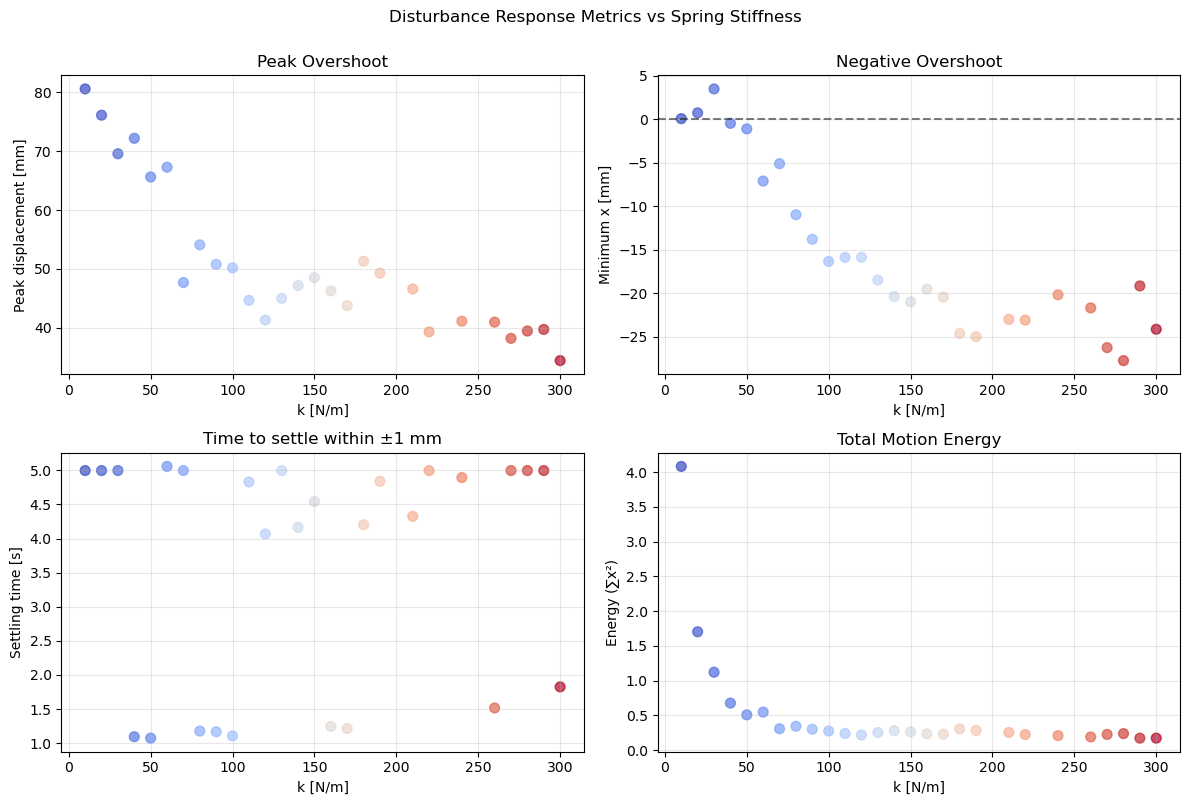

In [8]:
ks = np.array([m['k'] for m in metrics])
peaks = np.array([m['peak_disp'] for m in metrics])
settle_times = np.array([m['settle_time'] for m in metrics])
mins = np.array([m['min_x'] for m in metrics])
energies = np.array([m['energy'] for m in metrics])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].scatter(ks, peaks, c=ks, cmap='coolwarm', s=50, alpha=0.7)
axes[0, 0].set_xlabel('k [N/m]')
axes[0, 0].set_ylabel('Peak displacement [mm]')
axes[0, 0].set_title('Peak Overshoot')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].scatter(ks, mins, c=ks, cmap='coolwarm', s=50, alpha=0.7)
axes[0, 1].axhline(0, color='black', linestyle='--', alpha=0.5)
axes[0, 1].set_xlabel('k [N/m]')
axes[0, 1].set_ylabel('Minimum x [mm]')
axes[0, 1].set_title('Negative Overshoot')
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].scatter(ks, settle_times, c=ks, cmap='coolwarm', s=50, alpha=0.7)
axes[1, 0].set_xlabel('k [N/m]')
axes[1, 0].set_ylabel('Settling time [s]')
axes[1, 0].set_title('Time to settle within ±1 mm')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].scatter(ks, energies, c=ks, cmap='coolwarm', s=50, alpha=0.7)
axes[1, 1].set_xlabel('k [N/m]')
axes[1, 1].set_ylabel('Energy (∑x²)')
axes[1, 1].set_title('Total Motion Energy')
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle('Disturbance Response Metrics vs Spring Stiffness', fontsize=12, y=1.00)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig(os.path.join('outputs', 'disturbance_rejection', 'disturbance_metrics.pdf'))
plt.show()